# UPMaBoSS: population dynamics of the cell fate model

This notebook reproduces the analyses of the UPMaBoSS article
([Stoll et al., 2022](https://doi.org/10.3389/fmolb.2022.800152)) on the cell fate model of the
[MaBoSS website](https://maboss.curie.fr).

UPMaBoSS simulates the dynamics of a population of cells, taking into account both their intracellular and
intercellular regulations. The logical model of an individual cell is a MaBoSS model. At regular intervals,
the simulation is stopped, and the population is updated according to the nodes representing cell death and
cell division, and to the nodes accounting for signals coming from other cells. The simulation then continues
with the updated conditions, until the maximum time is reached.

The model is a modified version of the cell fate model of
[Calzone et al. (2010)](https://doi.org/10.1371/journal.pcbi.1000702): it accounts for the activation of TNFα by
NFκB, and includes two output nodes, `Division` and `Death`.

**Requirements:** [pyMaBoSS](https://pymaboss.readthedocs.io/), and the files `CellFateModel_uppmaboss.bnd`,
`CellFateModel_uppmaboss.cfg` and `CellFateModel_uppmaboss.upp`, in the same folder as this notebook.
The last section (the study of all the mutants) takes about half an hour.

In [1]:
import math
import os
import maboss
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.offsetbox import HPacker

# The figures are saved in the "figures" folder
os.makedirs("figures", exist_ok=True)
plt.rcParams.update({"savefig.dpi": 150, "savefig.bbox": "tight", "figure.constrained_layout.use": True})

def legend_below():
    """Move the legend of the current figure below the plot, in centered rows of similar widths."""
    figure, legend = plt.gcf(), plt.gca().get_legend()
    handles, labels = legend.legend_handles, [text.get_text() for text in legend.get_texts()]
    legend.remove()
    legend = figure.legend(handles, labels, loc="outside lower center", ncols=1)
    # Matplotlib fills the rows from the left: we rearrange the entries of the legend in centered rows,
    # as few as possible within the width of the plot, and of similar widths
    column = legend._legend_handle_box.get_children()[0]
    entries, column.align = column.get_children(), "center"
    sep = legend.columnspacing * legend.prop.get_size_in_points() * figure.dpi / 72
    widths = [entry.get_bbox(figure.canvas.get_renderer()).width + sep for entry in entries]
    max_width = 0.8 * figure.get_figwidth() * figure.dpi
    for n_rows in range(math.ceil(sum(widths) / max_width), len(entries) + 1):
        rows, row_widths = [[]], [0]
        for entry, width in zip(entries, widths):
            if rows[-1] and row_widths[-1] + width / 2 > sum(widths) / n_rows:
                rows.append([])
                row_widths.append(0)
            rows[-1].append(entry)
            row_widths[-1] += width
        if max(row_widths) <= max_width:
            break
    column._children = [HPacker(sep=sep, align="baseline", children=row) for row in rows]

## The model

Three files are needed:
* the model, `CellFateModel_uppmaboss.bnd`;
* the configuration file, `CellFateModel_uppmaboss.cfg`, with the transition rates, the simulation parameters and
  the initial conditions;
* the update file, `CellFateModel_uppmaboss.upp`, which describes the population updates.

In [3]:
from pathlib import Path

model_dir = "../data/model/CellFate/"
upp_file = model_dir + "CellFateModel_uppmaboss.upp"
# Search from the notebook working directory upward to find the project data folder
candidates = [
    Path.cwd(),
    Path.cwd().parent,
    Path.cwd().parent.parent,
]
model_dir = None
for base in candidates:
    candidate = base / "data" / "model" / "CellFate"
    if candidate.exists():
        model_dir = candidate
        break

if model_dir is None:
    raise FileNotFoundError(
        f"Could not find the CellFate model directory from {Path.cwd()} "
        "or its parent folders."
    )

model_dir = str(model_dir) + "/"
upp_file = str(Path(model_dir) / "CellFateModel_uppmaboss.upp")

model_WT = maboss.load(
    str(Path(model_dir) / "CellFateModel_uppmaboss.bnd"),
    str(Path(model_dir) / "CellFateModel_uppmaboss.cfg"),
)
print(open(upp_file).read())

death = Death;
division = Division ;
$TNF_induc u= $ProdTNF_NFkB*p[(NFkB,Death) = (1,0)];
steps = 48;
MaBoSS = MaBoSS



In [4]:
model_WT.network.names

['FASL',
 'TNF',
 'TNFR',
 'DISC_TNF',
 'DISC_FAS',
 'FADD',
 'RIP1',
 'RIP1ub',
 'RIP1K',
 'IKK',
 'NFkB',
 'CASP8',
 'BAX',
 'BCL2',
 'mROS',
 'ROS',
 'ATP',
 'MPT',
 'MOMP',
 'SMAC',
 'mcIAP',
 'cIAP',
 'Cyt_c',
 'mXIAP',
 'XIAP',
 'apoptosome',
 'CASP3',
 'cFLIP',
 'NonACD',
 'Apoptosis',
 'Survival',
 'Division',
 'Death']

In the update file:
* `death` and `division` give the nodes representing cell death and cell division;
* `$TNF_induc` is updated at each step with the proportion of living cells in which NFκB is active,
  multiplied by `$ProdTNF_NFkB`: this represents the production of TNFα by the cells in which NFκB is active,
  which then acts on the other cells;
* `steps` is the number of updates. With a duration of 1 hour for each step (`max_time = 1` in the
  configuration file), the population is simulated for 48 hours.

## MaBoSS simulation of the wild type

Before running UPMaBoSS, we run a MaBoSS simulation of the wild type model over 48 hours, without taking into
account cell death and division. It shows the behaviour of a single cell, and helps choosing the duration
of each step of UPMaBoSS: it should be smaller than the first transient effect.

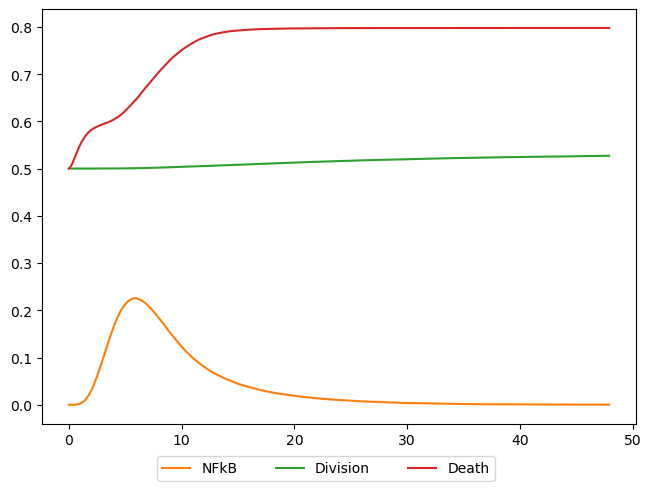

In [5]:
model_48h = maboss.copy_and_update_parameters(model_WT, {"max_time": 48})
model_48h.network.set_output(("Death", "Division", "NFkB"))
model_48h.run().plot_node_trajectory()
legend_below()
plt.savefig("figures/upmaboss_maboss_48h.png")

The first transient effects occur during the first hours: steps of 1 hour capture them.

## Population dynamics, with and without the paracrine feedback

We compare two conditions, after a pulse of TNFα at t = 0: with the paracrine feedback (NFκB activates TNFα,
which acts on the other cells), and without it (`$ProdTNF_NFkB = 0`). We follow the population ratio: the size of
the population relative to the initial one. It is indexed by the step number, which here is the time in hours.

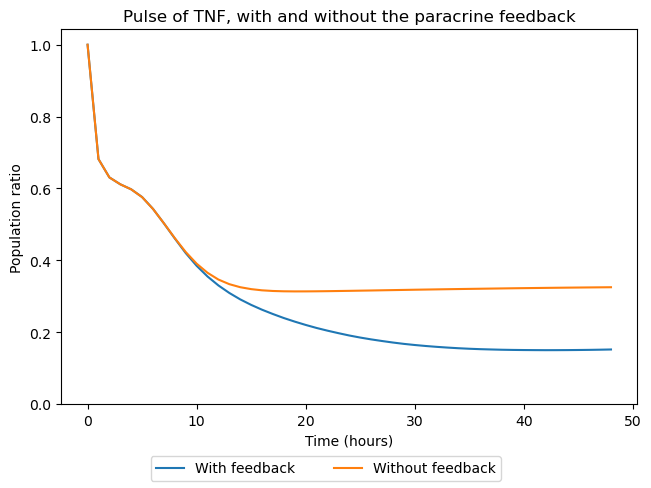

In [6]:
run_WT = maboss.UpdatePopulation(model_WT, upp_file).run("WT")

model_NoFB = maboss.copy_and_update_parameters(model_WT, {"$ProdTNF_NFkB": 0})
run_NoFB = maboss.UpdatePopulation(model_NoFB, upp_file).run("NoFB")

ratios = pd.DataFrame({
    "With feedback": run_WT.get_population_ratios(),
    "Without feedback": run_NoFB.get_population_ratios(),
})
ratios.plot(title="Pulse of TNF, with and without the paracrine feedback",
            xlabel="Time (hours)", ylabel="Population ratio", ylim=(0, None))
legend_below()
plt.savefig("figures/upmaboss_feedback.png")

The paracrine TNF loop leads to a significant decrease of the population size.

## Successive TNF treatments

We now simulate two successive treatments. During the first 48 hours, the cells receive a pulse of TNF at
t = 0, or no TNF. During the next 48 hours, the cells receive a constant TNF treatment (`$TNF_induc = 20`).
The second simulations start from the population at the end of the first ones (`previous_run`).

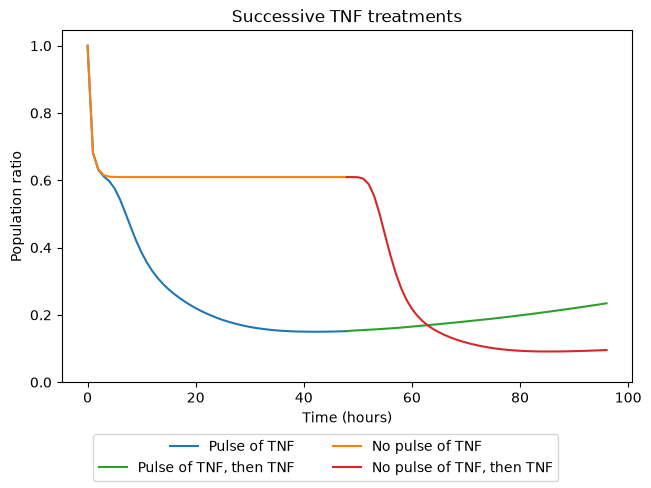

In [5]:
model_noTNF = model_WT.copy()
model_noTNF.network.set_istate("TNF", [1, 0])
run_noTNF = maboss.UpdatePopulation(model_noTNF, upp_file).run("noTNF")

model_TNF = maboss.copy_and_update_parameters(model_WT, {"$TNF_induc": 20})
run_reTNF = maboss.UpdatePopulation(model_TNF, upp_file, previous_run=run_WT).run("reTNF")
run_noTNF_reTNF = maboss.UpdatePopulation(model_TNF, upp_file, previous_run=run_noTNF).run("noTNF_reTNF")

ratios = pd.DataFrame({
    "Pulse of TNF": run_WT.get_population_ratios(),
    "No pulse of TNF": run_noTNF.get_population_ratios(),
    "Pulse of TNF, then TNF": run_reTNF.get_population_ratios(),
    "No pulse of TNF, then TNF": run_noTNF_reTNF.get_population_ratios(),
})
ratios.plot(title="Successive TNF treatments", xlabel="Time (hours)", ylabel="Population ratio", ylim=(0, None))
legend_below()
plt.savefig("figures/upmaboss_treatments.png")

The population that received an initial pulse of TNF is resistant to the second treatment: its population
ratio does not decrease, while the population which did not receive the initial pulse is strongly reduced.

## TNF resistance of the mutants

We study the conditions of TNF resistance by simulating the deletion of each internal node of the model.
For each mutant, we compute the relative effect of the second TNF treatment: the final population ratio with
the TNF treatment, divided by the one without it, for cells that received a pulse of TNF or not.

*This section takes about half an hour.*

In [6]:
def tnf_effect(model, name):
    """Relative effect of the second TNF treatment, with and without a first pulse of TNF."""
    model_nopulse = model.copy()
    model_nopulse.network.set_istate("TNF", [1, 0])
    model_tnf = maboss.copy_and_update_parameters(model, {"$TNF_induc": 20})

    effect = {}
    for first, first_model, workdir in [("Pulse TNF", model, "pulse"), ("No pulse TNF", model_nopulse, "nopulse")]:
        workdir = f"TNF_sensitivity/{name}/{workdir}"
        first_run = maboss.UpdatePopulation(first_model, upp_file).run(workdir)
        without_tnf = maboss.UpdatePopulation(model, upp_file, previous_run=first_run).run(workdir + "_noTNF")
        with_tnf = maboss.UpdatePopulation(model_tnf, upp_file, previous_run=first_run).run(workdir + "_TNF")
        effect[first] = with_tnf.get_population_ratios().iloc[-1] / without_tnf.get_population_ratios().iloc[-1]
    return effect

excluded = {"NonACD", "Apoptosis", "Survival", "Division", "Death", "TNF", "apoptosome"}
mutants = sorted(n for n in model_WT.network.names if n not in excluded)

effects = {"WT": tnf_effect(model_WT, "WT")}
for node in mutants:
    effects[f"{node} deletion"] = tnf_effect(maboss.copy_and_mutate(model_WT, [node], "OFF"), node)
effects = pd.DataFrame(effects).T
effects

,Pulse TNF,No pulse TNF
WT,1.022592,0.156856
ATP deletion,0.970833,1.104159
BAX deletion,1.041833,0.322199
BCL2 deletion,1.020593,0.152616
CASP3 deletion,1.061591,0.312033
CASP8 deletion,1.019385,0.331008
Cyt_c deletion,1.060628,0.309889
DISC_FAS deletion,1.022592,0.156856
DISC_TNF deletion,1.023142,0.328794
FADD deletion,1.025009,0.326944


The treatment has an effect when the relative change is below 1.

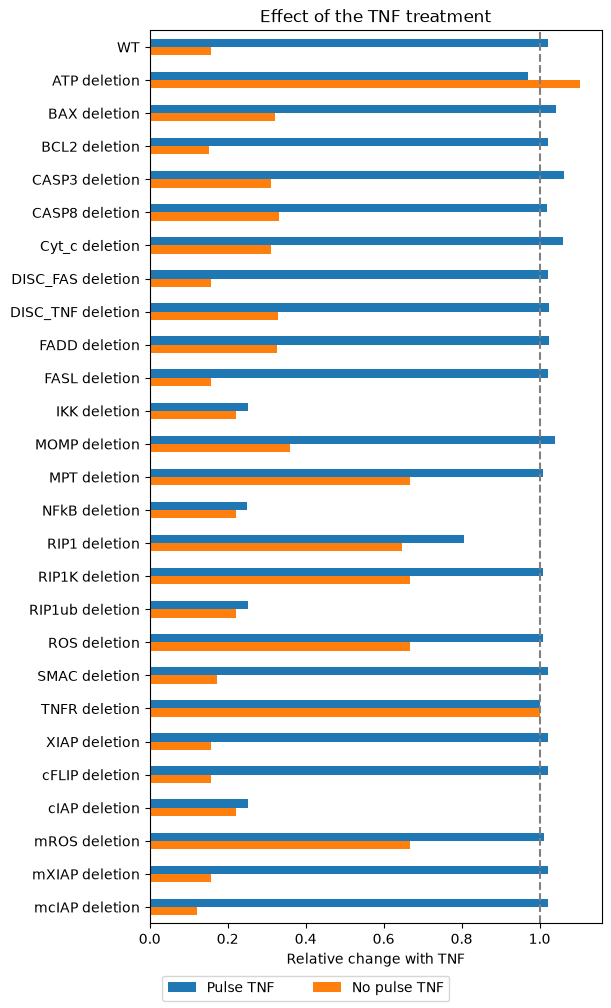

In [7]:
effects.plot.barh(figsize=(6, 10), title="Effect of the TNF treatment")
plt.xlabel("Relative change with TNF")
plt.axvline(1, color="grey", linestyle="--")
plt.gca().invert_yaxis()
legend_below()
plt.savefig("figures/upmaboss_mutants_effect.png")

* For a first group of mutants (the deletions of IKK, NFκB, cIAP or RIP1ub), there is no resistance: the TNF
  treatment reduces the population size, whether the cells received a pulse of TNF or not.
* For a second group, including the wild type (and for instance the BCL2 or XIAP deletions), the TNF treatment
  reduces the population size, but this effect disappears when the cells received a pulse of TNF: this indicates
  a resistance.
* Finally, the deletion of TNFR leads to insensitive cells, as expected (as does the deletion of ATP, but because
  all the cells die, whatever the treatment).